<a href="https://colab.research.google.com/github/TUIlmenauAMS/ADSP_Tutorials/blob/master/ADSP_01_Quantization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<p align="center">
    <img src="https://github.com/GuitarsAI/ADSP_Tutorials/blob/master/images/adsp_logo.png?raw=1">
</p>

### Prof. Dr. -Ing. Gerald Schuller <br> Jupyter Notebook: Renato Profeta



In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/9cBhNYULmGo" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

# Quantization

In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/gFCjY9tNg3s" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

**Quantization** is the process of mapping a continuous range of values into a finite range of discrete values.

In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/HsiRKPK1Cag" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

#### Python Example
Assume our A/D converter has an input range of -1V to 1V, 4 bit accuracy (meaning we have a total of $2^4$ codewords or indices), and the A/D converter has **0.2 V** at its **input**.

In [ ]:
# Stepsize
range_max=1   # Maximum input range
range_min=-1  # Minimum input range
N=4           # Number of bits

stepsize=(range_max-range_min)/(2**N)
stepsize

0.125

Next we get **quantization index** which is then encoded as a **codeword:**

In [ ]:
input_voltage=0.2
index =  round(input_voltage/stepsize)
index

2

**Observe:** If the quantization **stepsize is constant**, independent of the signal, we call it a “**uniform quantizer**”.<br>
The index then is **coded** using the 4 bits and sent to a decoder, for instance using the 4 bit binary **codeword** “0010”. The first bit usually is the sign bit. The **decoder reconstructs** the voltage by first decoding the codeword to an index, and for instance by **multiplying the index** with the **stepsize:**

In [ ]:
reconstr=stepsize*index
reconstr

0.25

This is also called the **(de-)quantized signal**, and its difference to the original value or signal is called the **quantization error**. In our example the quantization error is **Quantized Value – Original Value** =  0.25V-0.2V=**0.05 V**
<br>
**Observe:** There is always a range of voltages which is mapped to the same codeword. We call this range $\Delta$, or **stepsize**. These steps represent the quantization in the A/D conversion process, and they lead to quantization errors.<br>
The output after quantization is a linear **“Pulse Code Modulation” (PCM)** signal. It is linear in the sense that the code values are proportional to the input signal values.<br>


## Quantization Error

In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/qgFSD5fKPaE" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

Let's now call our quantization error “**e**”. Then the **quantization error power** is the **expectation** value of the squared quantization error **e**: <br>

$$ \large
E(e^2)=\int_{-\Delta /2}^{\Delta /2}e^2.p(e)de$$

where **$p(e)$** is the probability of error value **e**. Here we compute the power of each possible error value **e** by squaring it, and multiply it with its probability to obtain the **average power**.
<br><br>
This number will give us some impression of the signal quality after quantization, if we set it in **relation to the signal energy**.  Then we get a **Signal to Noise Ratio** (SNR) for our quantizer and A/D converter.<br>
Assume the quantization error **e** is uniformly distributed (all possible values of the quantization error e appear with equal probability), which is usually the case if the signal is much larger than the quantization step size $\Delta$ (large signal condition). Since the integral over the probabilities of all possible values of **e** must be 1, and the possible values of e are between $-\Delta /2$ and $\Delta /2$,

$$ \large
1=\int_{-\Delta /2}^{\Delta /2}p(e)de=p(e) \cdot \int_{-\Delta /2}^{\Delta /2}de=p(e) \cdot \Delta$$


we have

$$ \large p(e)=1/\Delta$$
which yields

$$ \large E(e^2)=\frac{1} {\Delta} \cdot \int_ {-\Delta/2} ^ {\Delta/2} e^2 de
= \frac{1} {\Delta} \left(\frac{(\Delta/2)^3} {3} - \frac{(-\Delta/2)^3} {3} \right) = \frac{\Delta^2}{12}$$

Hence the **quantization error power for a uniform quantizer** with stepsize $\Delta$ and with a large signal is:

$$ \large E(e^2)=\frac{\Delta^2}{12} $$

## Mid-Rise and Mid-Tread Quantization

In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/XagP9ixzRAg" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

Depending on if the quantizer has the input voltage 0 at the center of a quantization interval or on the boundary of that interval, we call the quantizer a mid-tread or a mid-rise quantizer, as illustrated in the following picture:

<center><img src="https://github.com/GuitarsAI/ADSP_Tutorials/blob/master/images/rise_tread_quantizers.png?raw=1"></center>
<font size="2">      
(From:http://eeweb.poly.edu/~yao/EE3414/quantization.pdf)
</font>

Here, $Q_i(f)$ is the index after quantization (which is then encoded and sent to the receiver), and Q(f) is the de-quantization, which produces the quantized reconstructed value at the receiver.<br><br>

This makes mainly a difference at **very small input values**. For the mid-rise quantizer, very small values are always quantized to +/- half the quantization interval ($\pm  \Delta/2$ ), whereas for the mid-tread quantizer, very small input values are always rounded to zero. You can also think about the **mid-rise** quantizer as **not having a zero** as a reconstruction value, but only very small positive and negative values.<br>

So the mid-rise can be seen as more accurate, because it also reacts to very small input values, and the mid-tread can be seen as saving bit-rate because it always quantizes very small values to zero.<br>

Observe that the expectation of the quantization error power for large signals stays the same for both types.

**Observe:**  the Mid-Tread quantizer “swallows” small signal levels, since they are all rounded to zero.
The Mid-Rise quantizer still captures small levels, but distorted.

#### Python Example

In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/tnKeSKOmEz4" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

In [ ]:
# Imports
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Signal Processing Parameters
Fs = 32000   # Sampling frequency
T=1/Fs       # Sampling Time

In [ ]:
# Input Signal
A=1
freq=500
n_period=1
period=np.round((1/freq)*n_period*Fs).astype(int)
t = np.arange(Fs+1)*T # Time vector
#help(np.arange)
sinewave = A*np.sin(2*np.pi*freq*t)

In [ ]:
# Quantization and De-quantization
N=4
stepsize=(1.0-(-1.0))/(2**N)
# Valid signed N-bit indices: -2**(N-1) ... 2**(N-1)-1  (here -8 ... 7)
min_index=-2**(N-1)
max_index=2**(N-1)-1
#Encode (clip to the valid index range)
sinewave_quant_rise_ind=np.clip(np.floor(sinewave/stepsize), min_index, max_index)
sinewave_quant_tread_ind=np.clip(np.round(sinewave/stepsize), min_index, max_index)
#Decode
sinewave_quant_rise_rec=sinewave_quant_rise_ind*stepsize+stepsize/2
sinewave_quant_tread_rec=sinewave_quant_tread_ind*stepsize

**Observe:** With $N$ bits we only have $2^N$ indices, here $-8 \dots 7$. The sine wave reaches exactly $1.0$ at its peak, which would need index $1.0/\Delta = 8$. That index does not exist, so we **clip** the indices to the valid range. This is called **overload** (or clipping): inputs beyond the largest reconstruction value produce an error larger than $\Delta/2$.

The two quantizers handle the range differently:
- **Mid-rise** reconstruction values are symmetric: $-0.9375 \dots 0.9375$ ($\pm 7.5\,\Delta$).
- **Mid-tread** reconstruction values are asymmetric: $-1.0 \dots 0.875$, because zero uses up one of the $2^N$ levels.

In [ ]:
# Shape for plotting
t_quant=np.delete(np.repeat(t[:period+1],2),-1)
sinewave_quant_rise_rec_plot=np.delete(np.repeat(sinewave_quant_rise_rec[:period+1],2),0)
sinewave_quant_tread_rec_plot=np.delete(np.repeat(sinewave_quant_tread_rec[:period+1],2),0)

In [ ]:
# Quantization Error
quant_error_tread=sinewave_quant_tread_rec-sinewave
quant_error_rise=sinewave_quant_rise_rec-sinewave

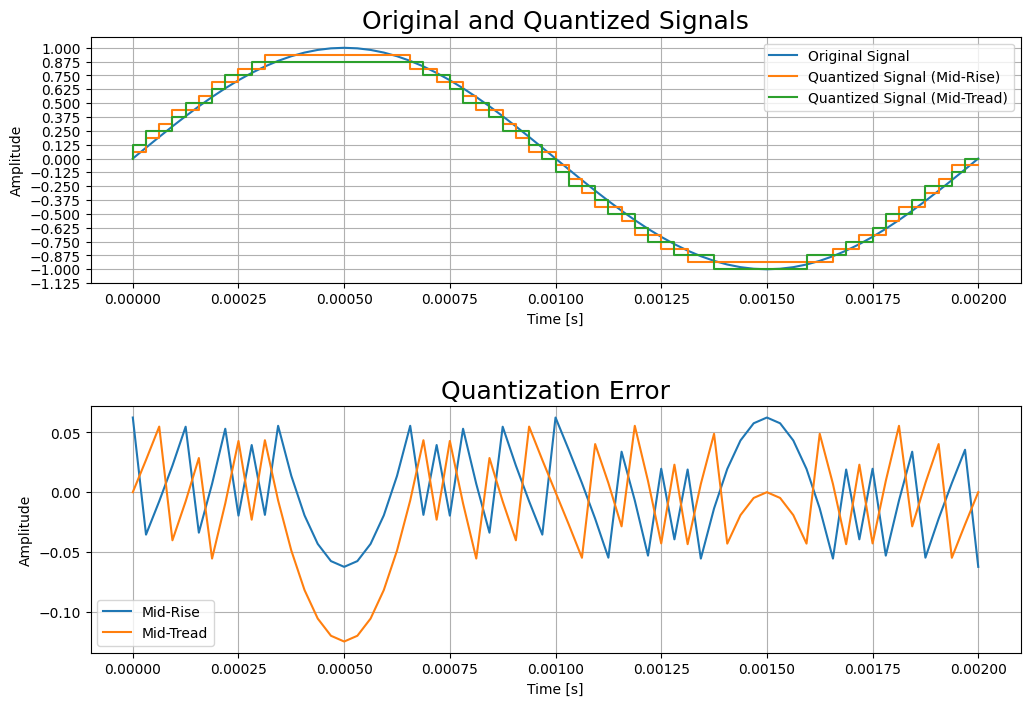

In [ ]:
%matplotlib inline
#plot
fig = plt.figure(figsize=(12,8))
plt.subplot(2,1,1)
plt.plot(t[:period+1],sinewave[:period+1], label='Original Signal')
plt.plot(t_quant,sinewave_quant_rise_rec_plot, label='Quantized Signal (Mid-Rise)')
plt.plot(t_quant,sinewave_quant_tread_rec_plot, label='Quantized Signal (Mid-Tread)')
plt.title('Original and Quantized Signals', fontsize=18)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.yticks(np.arange(-1-stepsize, 1+stepsize, stepsize))
plt.legend()
plt.grid()
plt.subplot(2,1,2)
plt.plot(t[:period+1],quant_error_rise[:period+1], label='Mid-Rise')
plt.plot(t[:period+1],quant_error_tread[:period+1], label='Mid-Tread')
plt.grid()
plt.title('Quantization Error', fontsize=18)
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
plt.legend()
plt.subplots_adjust(hspace=0.5)

In [ ]:
# Listen to Audio
# normalize=False plays every signal at its true level, so the quantization
# error sounds as quiet as it really is compared to the signal.
import IPython.display as ipd
print('Original Signal')
ipd.display(ipd.Audio(sinewave, rate=Fs, normalize=False))
print('Quantized Signal (Mid-Tread)')
ipd.display(ipd.Audio(sinewave_quant_tread_rec, rate=Fs, normalize=False))
print('Quantized Signal (Mid-Rise)')
ipd.display(ipd.Audio(sinewave_quant_rise_rec, rate=Fs, normalize=False))
print('Quantization Error (Mid-Tread)')
ipd.display(ipd.Audio(quant_error_tread, rate=Fs, normalize=False))
print('Quantization Error (Mid-Rise)')
ipd.display(ipd.Audio(quant_error_rise, rate=Fs, normalize=False))

Original Signal


Quantized Signal (Mid-Tread)


Quantized Signal (Mid-Rise)


Quantization Error (Mid-Tread)


Quantization Error (Mid-Rise)


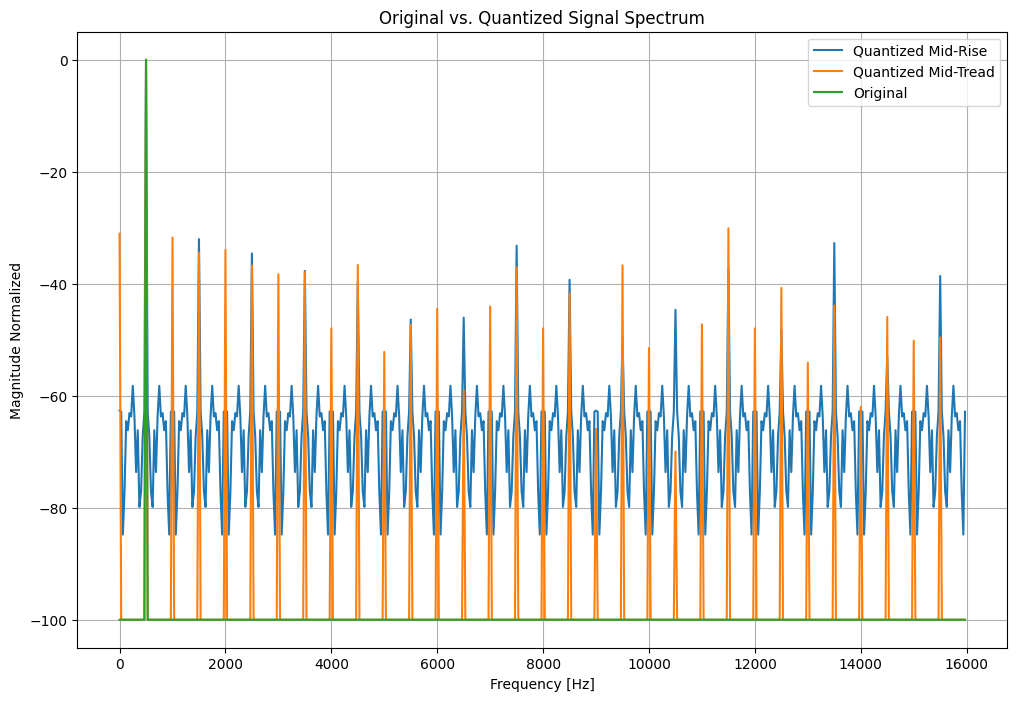

In [ ]:
# Signal Processing Parameters
NFFT=2**10
#Frequency Analysis
freqs = np.fft.fftfreq(NFFT, d=T) # Frequency bins
original_fft=np.fft.fft(sinewave, n=NFFT)
original_fft/=np.abs(original_fft).max()
quantized_tread_fft=np.fft.fft(sinewave_quant_tread_rec, n=NFFT)
quantized_tread_fft/=np.abs(quantized_tread_fft).max()
quantized_rise_fft=np.fft.fft(sinewave_quant_rise_rec, n=NFFT)
quantized_rise_fft/=np.abs(quantized_rise_fft).max()

# Plot
fig=plt.figure(figsize=(12,8))
plt.plot(freqs[0:NFFT//2],20*np.log10(np.abs(quantized_rise_fft[0:NFFT//2]).clip(min=1e-5)), label='Quantized Mid-Rise')
plt.plot(freqs[0:NFFT//2],20*np.log10(np.abs(quantized_tread_fft[0:NFFT//2]).clip(min=1e-5)), label='Quantized Mid-Tread')
plt.plot(freqs[0:NFFT//2],20*np.log10(np.abs(original_fft[0:NFFT//2]).clip(min=1e-5)), label='Original')
plt.grid()
plt.title('Original vs. Quantized Signal Spectrum')
plt.ylabel('Magnitude Normalized')
plt.xlabel('Frequency [Hz]')
plt.legend()
plt.show()

## Audio Example: Quantizing Your Own Recording

Based on the PyAudio real-time example by Gerald Schuller (October 2014), adapted to Jupyter by Renato Profeta (October 2019), and rewritten for Google Colab.

We record a few seconds of audio, quantize it with a **mid-tread** or **mid-rise** quantizer at a chosen bit depth, and listen to the result.

> **Note:** The cells in this section only run in **Google Colab**, because they use `google.colab` to record from the microphone in your browser. When running the notebook locally in Jupyter, use the original real-time PyAudio version from the [ADSP_Tutorials repository](https://github.com/GuitarsAI/ADSP_Tutorials) instead (`pip install pyaudio`; on Linux run `sudo apt install portaudio19-dev` first).

The video below walks through the original real-time PyAudio version. The code in this notebook is the Colab adaptation.

In [ ]:
%%html
<iframe width="560" height="315" src="https://www.youtube.com/embed/gSf8irnoW98" frameborder="0" allow="accelerometer; encrypted-media; gyroscope; picture-in-picture" allowfullscreen referrerpolicy="strict-origin-when-cross-origin"></iframe>

## Why not PyAudio?

The original notebook uses PyAudio to read from the microphone and write to the speakers in real time, block by block. Colab runs on a remote server with **no sound card**, so PyAudio cannot open any audio device there, even if it installs.

Instead:
1. The **browser** records from your microphone using JavaScript.
2. The recording is sent to the Colab kernel and decoded with `ffmpeg` to 16-bit PCM at 32 kHz.
3. We quantize it in Python and play it back with an audio player.

This is not real-time, but it lets you compare bit depths and quantizer types directly.

In [ ]:
from google.colab import output
from IPython.display import Javascript, display, Audio
from base64 import b64decode
import subprocess
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, Dropdown

RATE = 32000  # Sampling rate in Hz

# JavaScript recorder that runs in your browser, with a live status line
RECORD_JS = """
const sleep = ms => new Promise(r => setTimeout(r, ms));
const toDataURL = blob => new Promise(res => {
  const r = new FileReader(); r.onloadend = () => res(r.result); r.readAsDataURL(blob);
});
var record = ms => new Promise(async resolve => {
  const status = document.createElement('p');
  status.style.cssText = 'font-size:18px; font-weight:bold; font-family:sans-serif';
  status.textContent = '⏳ Opening microphone...';
  document.body.appendChild(status);

  const stream = await navigator.mediaDevices.getUserMedia({audio: true});
  const rec = new MediaRecorder(stream);
  const chunks = [];
  rec.ondataavailable = e => chunks.push(e.data);
  rec.onstop = async () => {
    stream.getTracks().forEach(t => t.stop());
    status.textContent = '✅ Recording finished, processing...';
    resolve(await toDataURL(new Blob(chunks)));
  };

  rec.start();
  const t0 = Date.now();
  const update = () => {
    const left = Math.max(0, (ms - (Date.now() - t0)) / 1000).toFixed(1);
    status.textContent = '🔴 Recording... speak now! ' + left + ' s left';
  };
  update();
  const timer = setInterval(update, 100);
  await sleep(ms);
  clearInterval(timer);
  rec.stop();
});
"""

def record(seconds=4, rate=RATE):
    """Record from the browser mic and return 16-bit samples as a float array."""
    # Inject the JS in the *current* cell's output, where eval_js runs
    display(Javascript(RECORD_JS))
    data_url = output.eval_js(f"record({int(seconds * 1000)})")
    webm = b64decode(data_url.split(",")[1])
    # Decode browser audio (webm/opus) to mono 16-bit PCM at the target rate
    pcm = subprocess.run(
        ["ffmpeg", "-loglevel", "quiet", "-i", "pipe:0",
         "-ac", "1", "-ar", str(rate), "-f", "s16le", "pipe:1"],
        input=webm, capture_output=True).stdout
    return np.frombuffer(pcm, dtype=np.int16).astype(float)

print("Setup complete.")

Setup complete.


## Record

Run the next cell. Your browser will ask for **microphone permission** the first time. Allow it, then speak or play some music for 4 seconds.

You can re-run this cell any time to make a new recording.

In [ ]:
samples = record(4)

print(f"{len(samples)} samples recorded, peak value: {np.max(np.abs(samples)):.0f} (max 32767)")
print("Original recording:")
display(Audio(samples / 2**15, rate=RATE, normalize=False))

## The two quantizers

With 16-bit input (range $-2^{15}$ to $2^{15}$) and a target bit depth $N$, the step size is

$$\Delta = \frac{2^{16}}{2^N}$$

**Mid-tread:** zero is a reconstruction value, so small signals become exact silence.

$$\hat{x} = \Delta \cdot \text{round}\left(\frac{x}{\Delta}\right)$$

**Mid-rise:** zero is a decision boundary, so even silence is reproduced as $\pm\Delta/2$.

$$\hat{x} = \Delta \cdot \left(\left\lfloor\frac{x}{\Delta}\right\rfloor + \frac{1}{2}\right)$$

For a full-scale sine wave, the signal-to-noise ratio is approximately $\text{SNR} \approx 6.02\,N + 1.76$ dB, so each extra bit adds about 6 dB. A real recording that doesn't use the full range will score lower.

In [ ]:
def quantize(x, N, quant_type):
    q = 2**16 / 2**N  # step size
    if quant_type == 'Mid-Tread':
        y = np.round(x / q) * q            # zero is a reconstruction value
    else:
        y = np.floor(x / q) * q + q / 2    # zero is a decision boundary
    return np.clip(y, -2**15, 2**15 - 1), q

def show(N=8, quant_type='Mid-Tread'):
    y, q = quantize(samples, N, quant_type)
    err = samples - y
    snr = 10 * np.log10(np.sum(samples**2) / np.sum(err**2))
    print(f"Stepsize: {q:.0f}   SNR: {snr:.1f} dB")

    seg = slice(RATE, RATE + 400)  # zoom into 400 samples after 1 s
    plt.figure(figsize=(10, 3))
    plt.plot(samples[seg], label='original')
    plt.step(range(400), y[seg], where='mid', label='quantized')
    plt.legend(); plt.xlabel('sample'); plt.ylabel('amplitude')
    plt.title(f'{quant_type}, N = {N} bits')
    plt.show()

    display(Audio(y / 2**15, rate=RATE, normalize=False))

interact(show,
         N=IntSlider(value=8, min=1, max=16, description='Bit-Depth:'),
         quant_type=Dropdown(options=['Mid-Tread', 'Mid-Rise'],
                             description='Type:'));

## Things to try

- **Lower the bit depth** from 16 down to 1 and listen to when the quantization noise becomes audible.
- **N = 1 to 3, Mid-Tread:** quiet passages and pauses turn into **silence**, because small values round to zero.
- **N = 1 to 3, Mid-Rise:** the pauses become a **buzzing noise**, because zero is not a possible output value.
- **Check the 6 dB rule:** note the SNR at N = 8, 9, 10. Does it grow by about 6 dB per bit?
- **Record quietly vs. loudly:** a quiet recording has a lower SNR at the same bit depth, because it uses fewer quantization levels.